# Frozen global-to-Lebanon model benchmarks
This notebook reviews actual completed CPU experiments: seasonal climatology, logistic regression, random forests, extra trees, histogram boosting and three dense neural architectures. There are 89 validation candidates and 58 retained stage winners plus nine conservative-policy controls. Thresholds and choices are fixed before reserved scoring. No test-driven tuning occurs here. All results concern a retrospective, coverage-conditioned satellite-detection target.

In [1]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image
from firecast.benchmark_global import load_part, score
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
CORE = ROOT / 'outputs/global-transfer-benchmark'
FINAL = ROOT / 'outputs/global-final-refit'
summary = json.loads((ROOT / 'docs/global-results.json').read_text())
core = json.loads((CORE / 'benchmark-results.json').read_text())
final = json.loads((FINAL / 'results.json').read_text())
selection_bytes = (CORE / 'selection-frozen.json').read_bytes()
assert hashlib.sha256(selection_bytes).hexdigest() == core['selection_file_sha256']
print('Validation-selected global winner:', core['selection']['best_global'])
print('Validation-selected transfer winner:', core['selection']['best_transfer'])
print('Validation-selected overall Lebanese winner:', core['selection']['best_lebanon_overall'])
print('Production approved:', summary['release']['approved'])

Validation-selected global winner: strict-neural_128_64_32-global_calibration-sigmoid
Validation-selected transfer winner: strict-neural_64_32-ensemble-0.75
Validation-selected overall Lebanese winner: strict-neural_64_32-lebanon_only-1
Production approved: False


## Model and adaptation choices
The trainer evaluates source and local-only controls, global/local sigmoid calibration, global/local ensembles, anchored linear optimization, pretrained-score local trees, pooled training and actual neural weight continuation. Neural adaptation keeps the global scaler and changes pretrained weights. Class-balanced/positive-weighted variants are recalibrated on natural-prevalence calibration data; this does not guarantee good future probabilities. The best transfer stage is a 75% local / 25% global 64–32 neural ensemble, not the actual weight-continuation variant. A local-only network won overall Lebanese validation.

In [2]:
validation = pd.DataFrame([dict(id=r['id'], family=r['family'], stage=r['stage'], global_AP=r['global_validation']['pr_auc_average_precision'], Lebanese_AP=r['lebanon_validation']['pr_auc_average_precision'], Lebanese_Brier=r['lebanon_validation']['brier']) for r in json.loads((CORE / 'validation-results.json').read_text())])
assert len(validation) == 89
display(validation.groupby(['family','stage']).size().rename('candidates').to_frame())
display(validation.sort_values('Lebanese_AP', ascending=False).head(10))
# Reproduction uses the shared trainer, not a notebook implementation:
# from firecast.benchmark_global import benchmark
# benchmark(ROOT / 'outputs/global-transfer-data', ROOT / 'outputs/reproduced-global-benchmark')

candidates
family            stage                              
extra_trees       ensemble                          2
                  global                            2
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      2
                  lebanon_only_calibrated           1
                  local_adaptation                  1
gradient_boosting ensemble                          2
                  global                            2
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      2
                  lebanon_only_calibrated           1
                  local_adaptation                  1
                  pooled                            1
logistic          ensemble                          2
                  global                            3
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      3
                  lebanon_only_calibrated           1
                  local_adaptation                  2
                  pooled                            1
neural_128_64_32  ensemble                          2
                  global                            2
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      2
                  lebanon_only_calibrated           1
                  local_adaptation                  3
neural_32         ensemble                          2
                  global                            2
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      2
                  lebanon_only_calibrated           1
                  local_adaptation                  3
neural_64_32      ensemble                          2
                  global                            2
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      2
                  lebanon_only_calibrated           1
                  local_adaptation                  3
                  pooled                            1
random_forest     ensemble                          2
                  global                            2
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      2
                  lebanon_only_calibrated           1
                  local_adaptation                  1
seasonal          ensemble                          2
                  global                            1
                  global_calibration                1
                  lebanon_calibration               1
                  lebanon_only                      1
                  lebanon_only_calibrated           1

,id,family,stage,global_AP,Lebanese_AP,Lebanese_Brier
67,strict-neural_64_32-lebanon_only-1,neural_64_32,lebanon_only,0.012260,0.006379,0.000836
70,strict-neural_64_32-lebanon_only_calibrated-si...,neural_64_32,lebanon_only_calibrated,0.013649,0.006379,0.000843
72,strict-neural_64_32-ensemble-0.75,neural_64_32,ensemble,0.142907,0.006243,0.000836
75,strict-neural_64_32-local_adaptation-10epochs_...,neural_64_32,local_adaptation,0.046382,0.004012,0.000842
38,strict-extra_trees-ensemble-0.25,extra_trees,ensemble,0.114285,0.003780,0.000838
39,strict-extra_trees-ensemble-0.75,extra_trees,ensemble,0.026867,0.003766,0.000839
37,strict-extra_trees-lebanon_only_calibrated-sig...,extra_trees,lebanon_only_calibrated,0.019170,0.003754,0.000840
34,strict-extra_trees-lebanon_only-1,extra_trees,lebanon_only,0.019170,0.003754,0.034463
32,strict-extra_trees-lebanon_only-0,extra_trees,lebanon_only,0.021058,0.003644,0.000831
73,strict-neural_64_32-local_adaptation-5epochs_w...,neural_64_32,local_adaptation,0.097447,0.003565,0.000838


## Before/after on BOTH domains
Each displayed family's transfer stage was chosen on Lebanese validation, not by selecting the largest test score. The global temporal and geographic tests show transfer/forgetting. Lebanese 2023–2025 is a previously viewed historical benchmark with new conflict exclusions; it is not freshly untouched evidence.

,domain,observations,positive_windows,pr_auc_average_precision,brier,precision,recall,f1
288,global_validation,133335,1922,0.142907,0.013737,0.181794,0.358481,0.241246
289,lebanon_validation,38560,32,0.006243,0.000836,0.090909,0.031250,0.046512
290,global_temporal,413614,5023,0.160365,0.011376,0.179876,0.415688,0.251097
291,global_geographic,119728,1458,0.044759,0.011984,0.049196,0.069273,0.057533
292,lebanon_known_benchmark,95751,137,0.006978,0.001428,0.022222,0.007299,0.010989
293,lebanon_fresh_confirmation,24237,15,0.002586,0.000626,0.000000,0.000000,0.000000


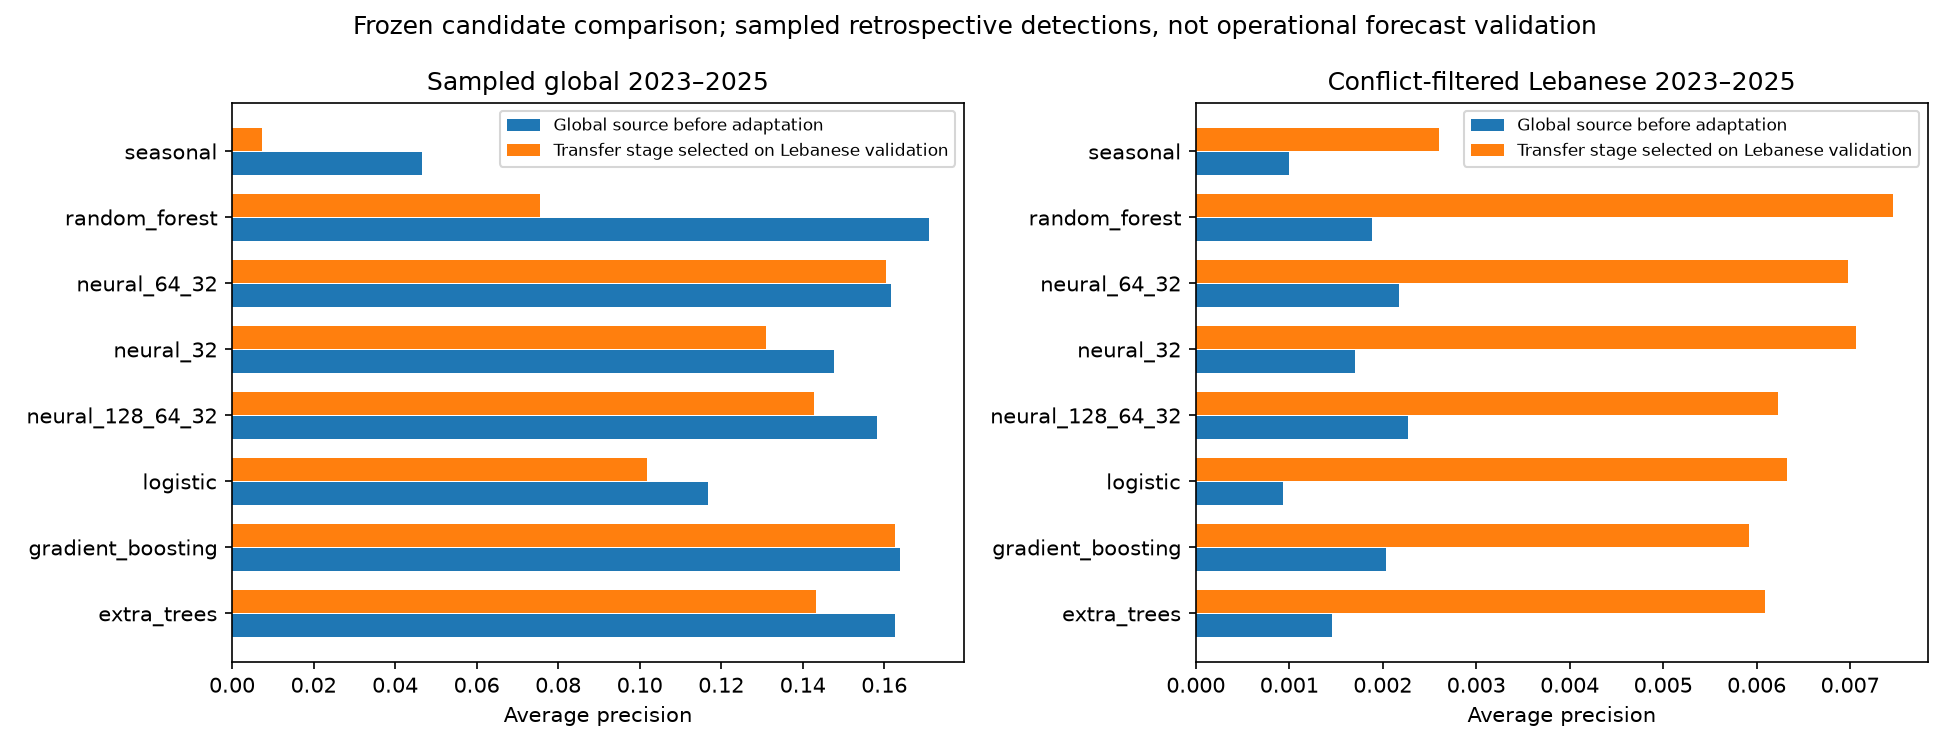

In [3]:
table = pd.read_csv(ROOT / 'docs/global-benchmark.csv')
display(table[table.id.eq(core['selection']['best_transfer'])][['domain','observations','positive_windows','pr_auc_average_precision','brier','precision','recall','f1']])
display(Image(filename=str(ROOT / 'docs/figures/global-before-after.png')))

## Fixed refit using more available past data
Without using confirmation scores to choose a new recipe, the selected settings were refitted on 2018–2024 data and calibrated on 2025. This uses 949,823 global / 260,804 Lebanese fitting windows. New global 2026 data provide additional temporal/geographic confirmation. The Lebanese 2026 fold had already been automatically scored by the first benchmark and is explicitly a repeated fixed-fold comparison for this refit, not a newly independent test. Carry-forward and calibration-period decision thresholds are recorded separately.

Refit fitting rows: 949823 260804
Separate 2025 calibration rows: 129656 28808


,model,domain,observations,positive_windows,pr_auc_average_precision,brier,precision,recall,f1,threshold,prevalence,mean_probability,site_macro_average_precision
0,refit_matching_global_source,global_2026_temporal,113942,1402,0.158682,0.011185,0.234624,0.220399,0.227289,2.101028e-01,0.012305,1.432983e-02,0.047914
1,refit_matching_global_source,global_2026_geographic,34407,604,0.097024,0.016589,0.000000,0.000000,0.000000,2.101028e-01,0.017555,9.846930e-03,0.039525
2,refit_matching_global_source,lebanon_2026_fixed_fold,24237,15,0.000632,0.000625,0.000000,0.000000,0.000000,1.880012e-02,0.000619,1.435204e-03,0.000632
3,refit_selected_transfer,global_2026_temporal,113942,1402,0.157189,0.011702,0.232681,0.220399,0.226374,4.859398e-02,0.012305,3.457217e-03,0.045635
4,refit_selected_transfer,global_2026_geographic,34407,604,0.097024,0.017205,0.000000,0.000000,0.000000,4.859398e-02,0.017555,2.339771e-03,0.039525
5,refit_selected_transfer,lebanon_2026_fixed_fold,24237,15,0.003091,0.000619,0.000000,0.000000,0.000000,8.092745e-02,0.000619,1.151177e-03,0.003091
6,refit_matching_local_control,global_2026_temporal,113942,1402,0.010945,0.012306,0.012305,1.000000,0.024310,0.000000e+00,0.012305,1.140632e-04,0.017677
7,refit_matching_local_control,global_2026_geographic,34407,604,0.017500,0.017555,0.017555,1.000000,0.034503,0.000000e+00,0.017555,7.045730e-09,0.021320
8,refit_matching_local_control,lebanon_2026_fixed_fold,24237,15,0.003372,0.000620,0.000000,0.000000,0.000000,1.170917e-01,0.000619,1.099759e-03,0.003372
9,refit_matching_local_calibrated,global_2026_temporal,113942,1402,0.011854,0.012306,0.012305,1.000000,0.024310,1.745761e-07,0.012305,1.241281e-04,0.017481


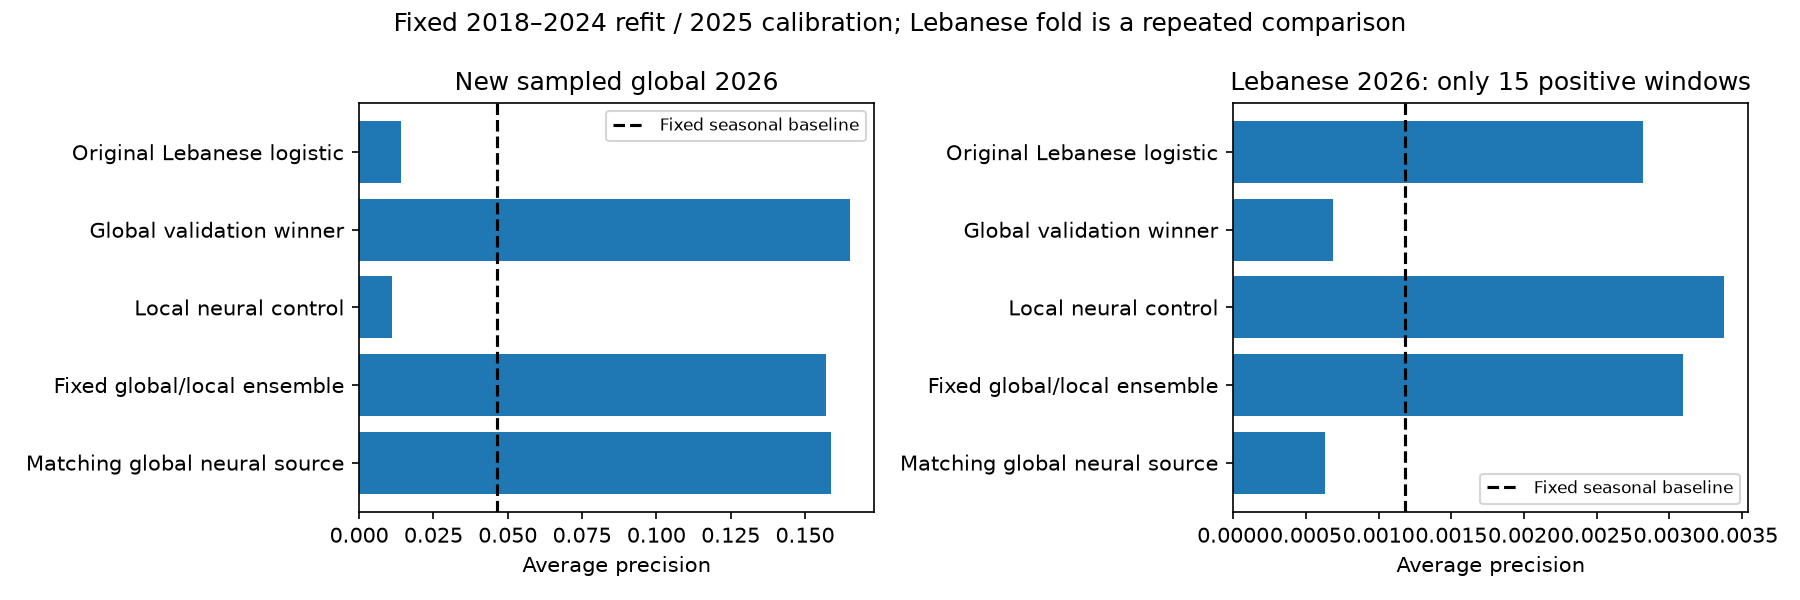

In [4]:
frozen = json.loads((FINAL / 'refit-frozen.json').read_text())
for name, record in frozen['artifacts'].items():
    assert hashlib.sha256((FINAL / 'frozen' / record['file']).read_bytes()).hexdigest() == record['sha256']
print('Refit fitting rows:', frozen['global_fit_windows'], frozen['local_fit_windows'])
print('Separate 2025 calibration rows:', frozen['calibration_global_windows'], frozen['calibration_lebanon_windows'])
display(pd.read_csv(FINAL / 'results.csv'))
display(Image(filename=str(ROOT / 'docs/figures/global-refit-2026.png')))

## Recompute selected diagnostics without fitting
This reproduces stored measurements only. The earlier comparison has already exposed these outcomes, so rerunning it does not create a new confirmation. No algorithm, weights, calibrator or threshold is changed. Fifteen positive Lebanese windows provide little statistical power. The selected transfer detected none at its frozen threshold and did not beat the matching local-only control.

Lebanese fixed fold: 24237 windows / 15 positive windows
Confusion TN/FP/FN/TP: [24222, 0, 15, 0]
Paired transfer versus local diagnostic: {'AP_difference_transfer_minus_local': -0.00028150114159482134, 'paired_month_block_95pct': [-0.0007042758801270961, -4.8577824256874864e-05], 'resamples': 100, 'note': 'Diagnostic only; 15 positives and 10 months make inference unstable'}


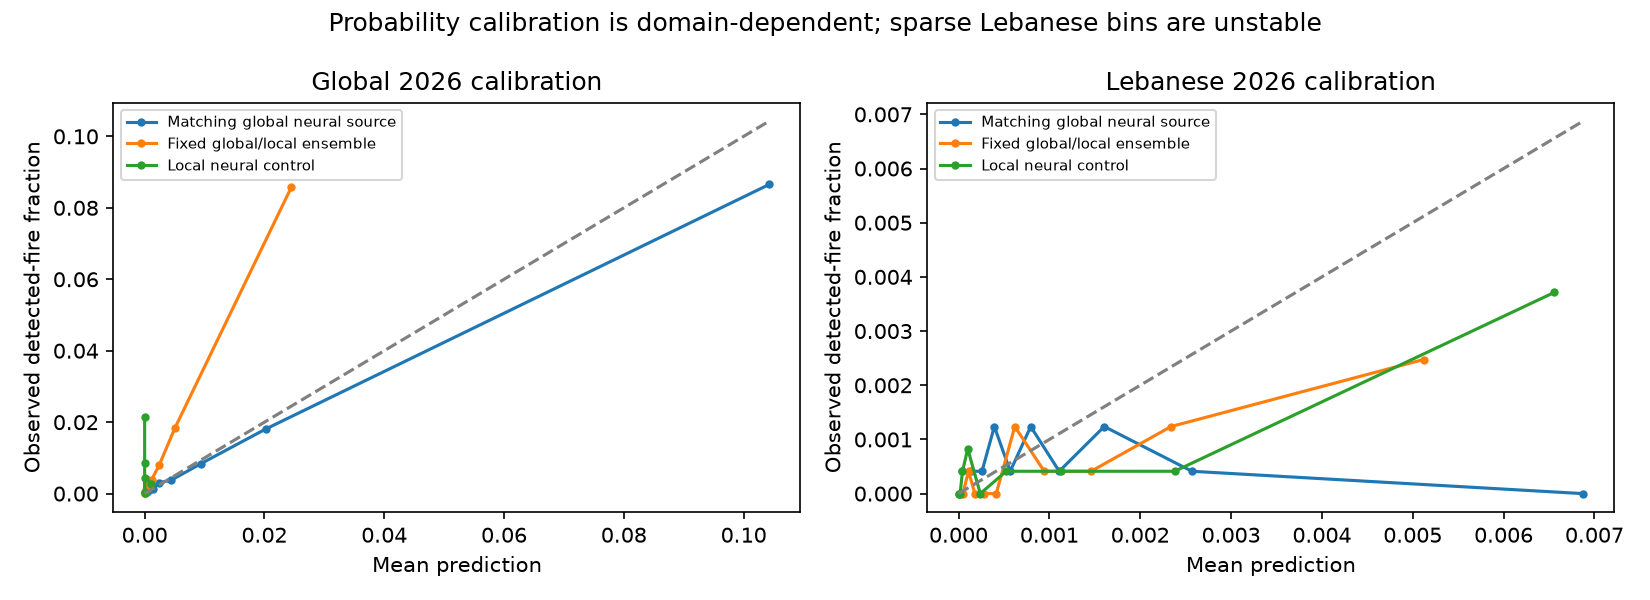

In [5]:
manifest = json.loads((ROOT / 'outputs/global-transfer-data/dataset-manifest.json').read_text())
f = load_part(ROOT / 'outputs/global-transfer-data', 'lebanon-confirmation-sealed', manifest)
artifact = joblib.load(FINAL / 'selected-research.joblib')
p = artifact['model'].predict_proba(f)[:,1]
measured = score(f, p, artifact['threshold'])
expected = final['results']['refit_selected_transfer']['lebanon_2026_fixed_fold']
assert np.isclose(measured['pr_auc_average_precision'], expected['pr_auc_average_precision'])
assert measured['confusion_matrix_tn_fp_fn_tp'] == expected['confusion_matrix_tn_fp_fn_tp']
print('Lebanese fixed fold:', measured['observations'], 'windows /', measured['positive_windows'], 'positive windows')
print('Confusion TN/FP/FN/TP:', measured['confusion_matrix_tn_fp_fn_tp'])
print('Paired transfer versus local diagnostic:', summary['paired_comparison'])
display(Image(filename=str(ROOT / 'docs/figures/global-calibration.png')))

## Actual forecast and the release boundary
The research view uses a genuine complete NASA GEOS issued window plus already available seven/thirty-day antecedent history. It withholds the 32 conflict-excluded cells, keeps source-transfer/retrospective/coverage warnings on all outputs and is not approved for service deployment. The input date does not turn retrospective evaluation into operational skill.

,cell_id,prediction_time,probability,flags
0,1230_2151,2026-11-15 00:00:00+00:00,NaN,outside_validated_weather_source;outside_confl...
1,1242_2161,2026-11-15 00:00:00+00:00,0.000078,outside_validated_weather_source;RETROSPECTIVE...
2,1242_2160,2026-11-15 00:00:00+00:00,0.000693,outside_validated_weather_source;RETROSPECTIVE...
3,1242_2159,2026-11-15 00:00:00+00:00,0.001046,outside_validated_weather_source;RETROSPECTIVE...
4,1242_2158,2026-11-15 00:00:00+00:00,0.002811,outside_validated_weather_source;RETROSPECTIVE...


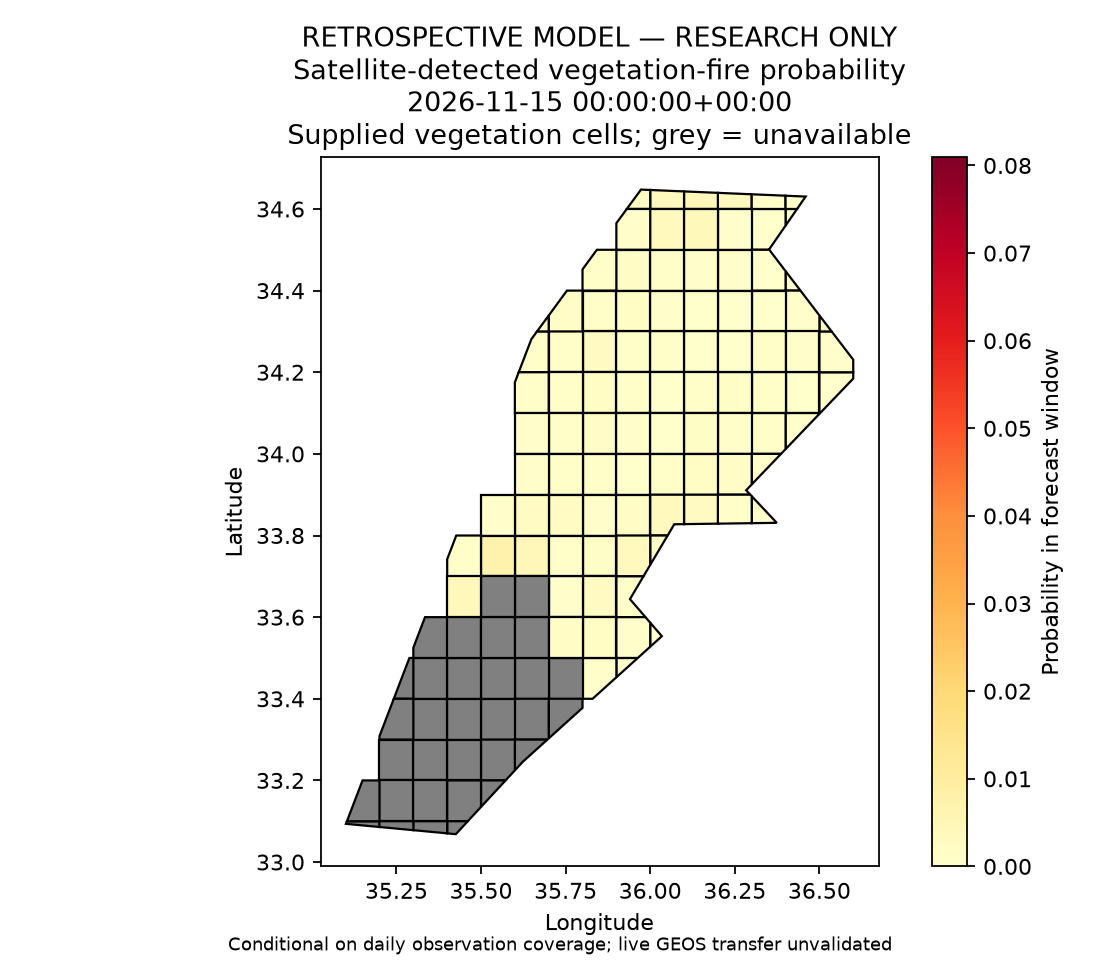

Failed release checks: ['operational_forecast_mode', 'historical_feature_availability', 'issued_forecast_backtest', 'independent_incident_split_review', 'calibration_review', 'test_sample_size', 'test_span']


In [6]:
risk = pd.read_csv(FINAL / 'live-research-risk/risk.csv')
assert len(risk) == 124 and risk.probability.isna().sum() == 32
assert risk['flags'].str.contains('RETROSPECTIVE_MODEL_NOT_OPERATIONALLY_VALIDATED').all()
display(risk[['cell_id','prediction_time','probability','flags']].head())
display(Image(filename=str(ROOT / 'docs/figures/global-transfer-research-forecast.png')))
print('Failed release checks:', summary['release']['failures'])

## Limits and next confirmation
Global data helped relative to zero-shot Lebanese transfer but did not establish an advantage over local-only fitting. Domain calibration and geographic transfer remain weak. This sampled panel is not whole-Earth validation. Cloud/observation selection, incomplete ignition/facility/conflict labels, later reprocessed vegetation, sparse positives and the missing issued-weather backtest remain unresolved. All 2026 results are now known; further development needs a newly reserved confirmation design. Read `../docs/global-results.md`, `../docs/global-statecharts.md` and `../../decisions.md`.